In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pickle
import json
import os
import pandas as pd
from IPython.display import display
from torch.utils.data import DataLoader

from src.trainer_dann import TrainerLSTM, TrainerDANN
from src.utils import evaluation
from src.config import NATIVE_MODEL_BY_DOMAIN, DEVICE

c:\Users\alice\master_thesis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
results_dict = {"frame_bilstm_sampler": "outputs/results/frame_bilstm_sampler", "frame_dann_bilstm_sampler": "outputs/results/frame_dann_bilstm_sampler"}
all_reports = {}

Confusion Matrices for frame_bilstm_sampler experiment


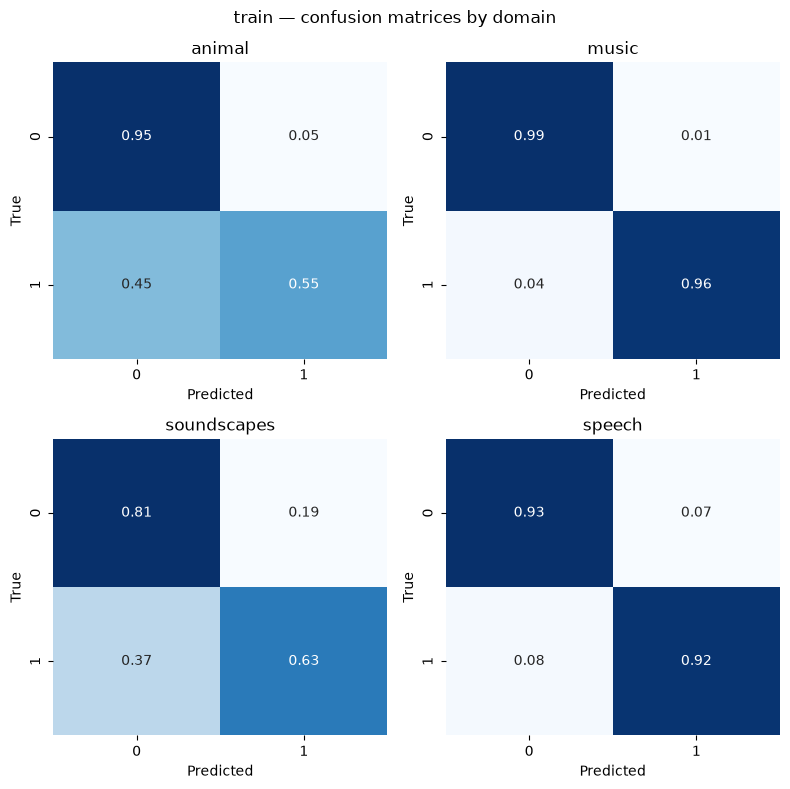

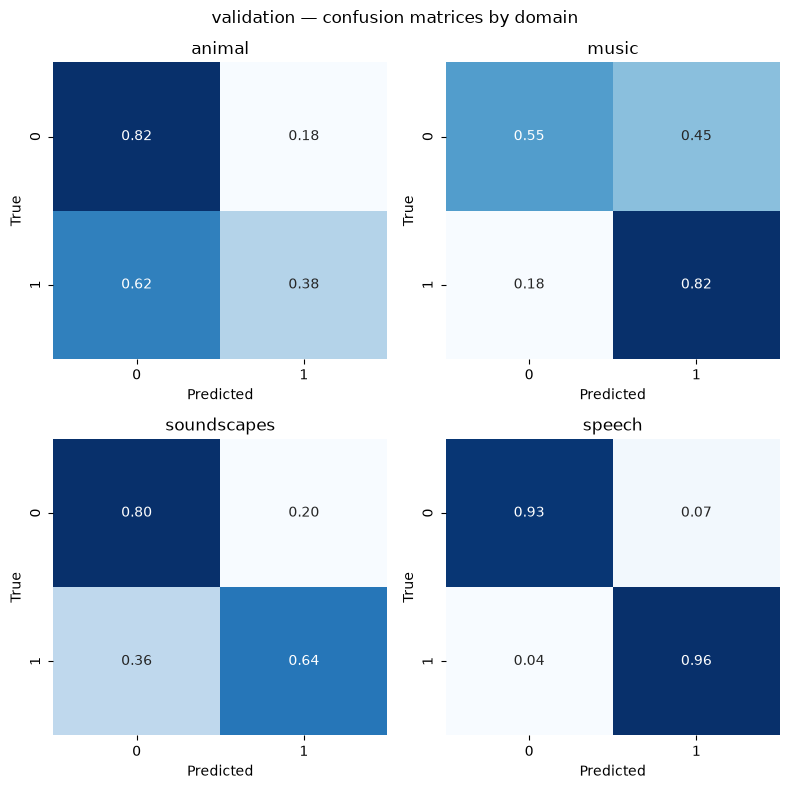

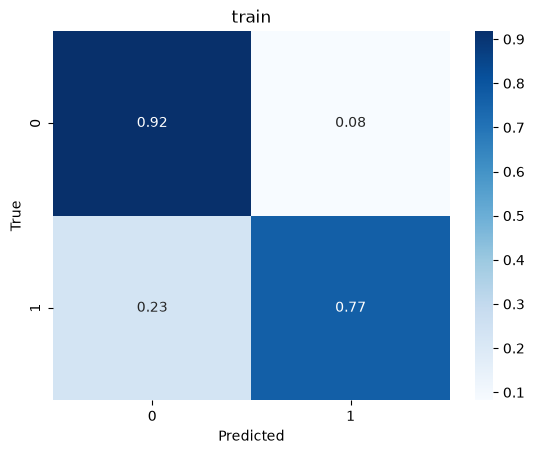

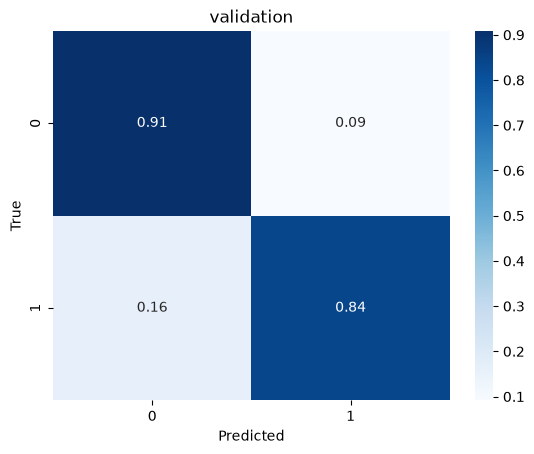

Confusion Matrices for frame_dann_bilstm_sampler experiment


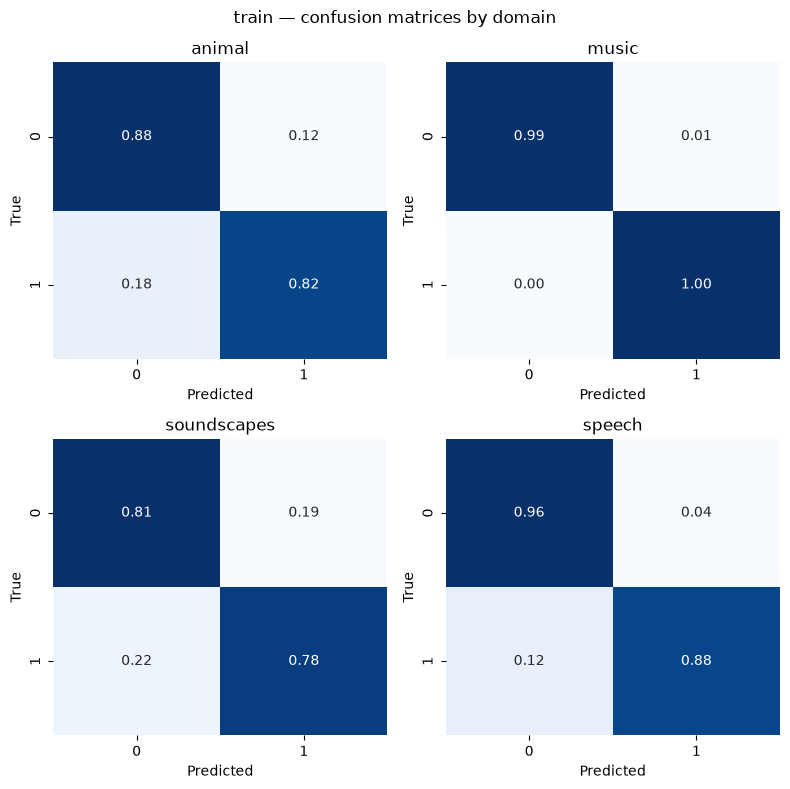

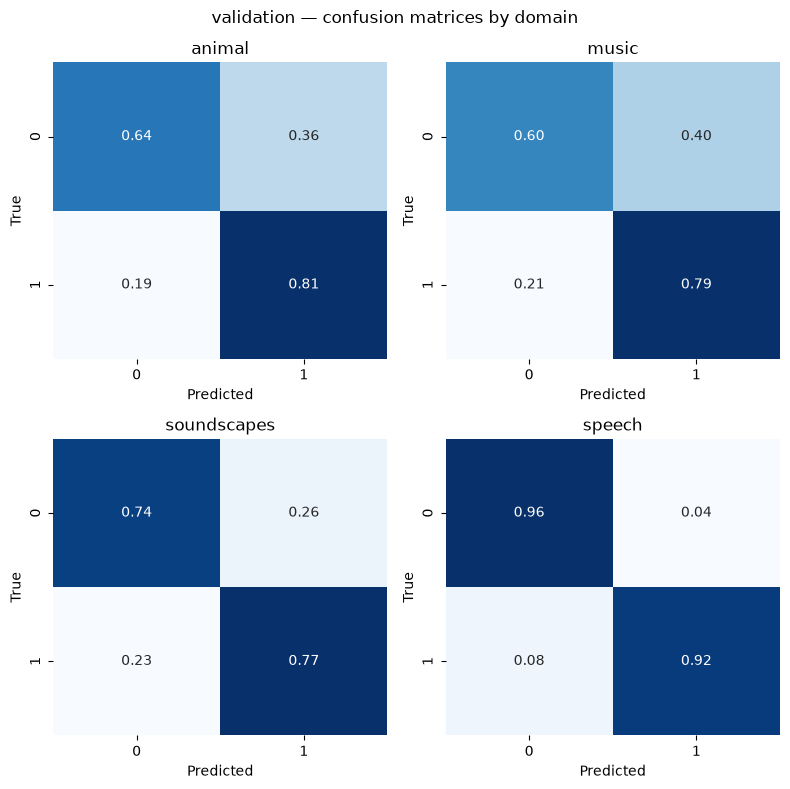

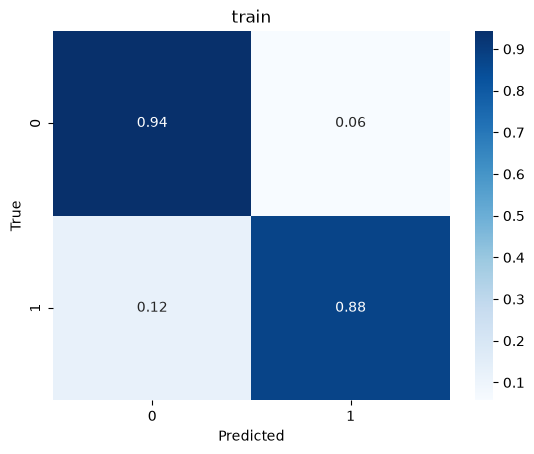

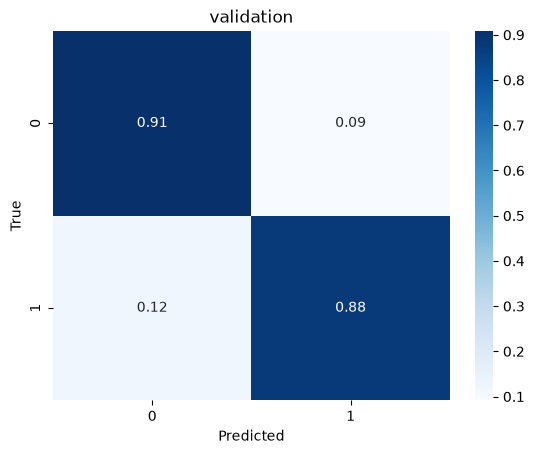

In [3]:
for run in ("frame_bilstm_sampler", "frame_dann_bilstm_sampler"):
    splits = [("train", f"{results_dict[run]}/train_results.pt"), ("validation", f"{results_dict[run]}/validation_results.pt")]

    conf_mat_outdir = os.path.join("outputs/plots/confusion_matrices", run)
    tables_outdir = os.path.join("outputs/tables", run)

    for d in (conf_mat_outdir, tables_outdir):
        os.makedirs(d, exist_ok=True)


    reports = evaluation.compute_classification_reports(None, splits)
    all_reports[run] = reports
    #display_classification_reports(reports)

    with open(f"outputs/tables/{run}/classification_reports.json", "w") as f:
        json.dump(reports, f, indent=2)

    print(f"Confusion Matrices for {run} experiment")
    for split_name, pt_path in splits:
        evaluation.save_combined_confusion_matrix(None, pt_path, split_name, output_dir=f"plots/confusion_matrices/{run}")

    evaluation.save_confusion_matrices(None, splits)


In [4]:
for split_name in ("train", "validation"):
    tables = {}
    for run in ("frame_bilstm_sampler", "frame_dann_bilstm_sampler"):
        tables[run] = evaluation.build_summary_table(all_reports[run], split_name=split_name)

    comparison = pd.concat(tables, axis=1)
    print(split_name)
    display(comparison)
    

train


frame_bilstm_sampler                                    \
                        accuracy balanced_accuracy precision_macro   
domain                                                               
animal                  0.753329          0.753040        0.802340   
music                   0.975649          0.975614        0.975901   
soundscapes             0.721524          0.719977        0.727452   
speech                  0.922495          0.922462        0.922582   

                                   frame_dann_bilstm_sampler  \
            recall_macro  f1_macro                  accuracy   
domain                                                         
animal          0.753040  0.742768                  0.871585   
music           0.975614  0.975644                  0.996737   
soundscapes     0.719977  0.718715                  0.793602   
speech          0.922462  0.922485                  0.941725   

                                                                      
            balanced_accuracy precision_macro recall_macro  f1_macro  
domain                                                                
animal               0.854182        0.801263     0.854182  0.822122  
music                0.995838        0.995838     0.995838  0.995838  
soundscapes          0.793618        0.793919     0.793618  0.793552  
speech               0.919422        0.906698     0.919422  0.912853

validation


frame_bilstm_sampler                                    \
                        accuracy balanced_accuracy precision_macro   
domain                                                               
animal                  0.714286          0.597903        0.599794   
music                   0.753247          0.687281        0.681548   
soundscapes             0.721311          0.721311        0.727423   
speech                  0.936638          0.943661        0.886561   

                                   frame_dann_bilstm_sampler  \
            recall_macro  f1_macro                  accuracy   
domain                                                         
animal          0.597903  0.598806                  0.679365   
music           0.687281  0.684222                  0.740260   
soundscapes     0.721311  0.719426                  0.754098   
speech          0.943661  0.910540                  0.952989   

                                                                      
            balanced_accuracy precision_macro recall_macro  f1_macro  
domain                                                                
animal               0.724907        0.662415     0.724907  0.648021  
music                0.694737        0.674528     0.694737  0.681818  
soundscapes          0.754098        0.754372     0.754098  0.754032  
speech               0.941249        0.920370     0.941249  0.930274

FRAME_BILSTM_SAMPLER


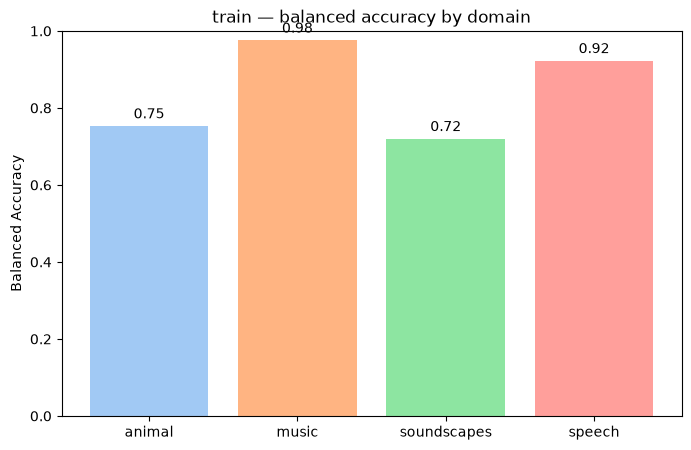

FRAME_BILSTM_SAMPLER


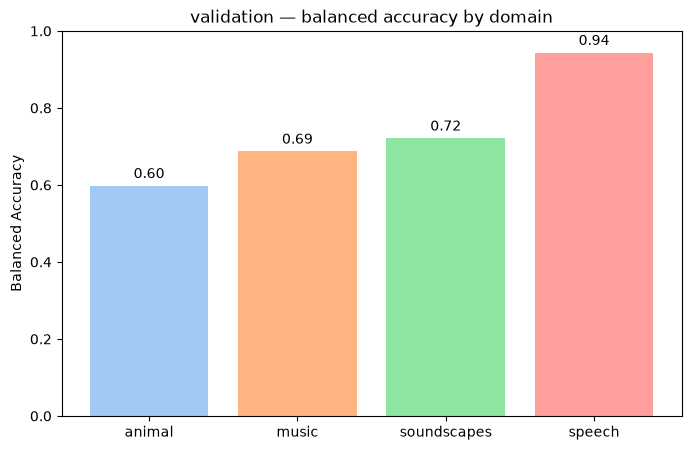

FRAME_DANN_BILSTM_SAMPLER


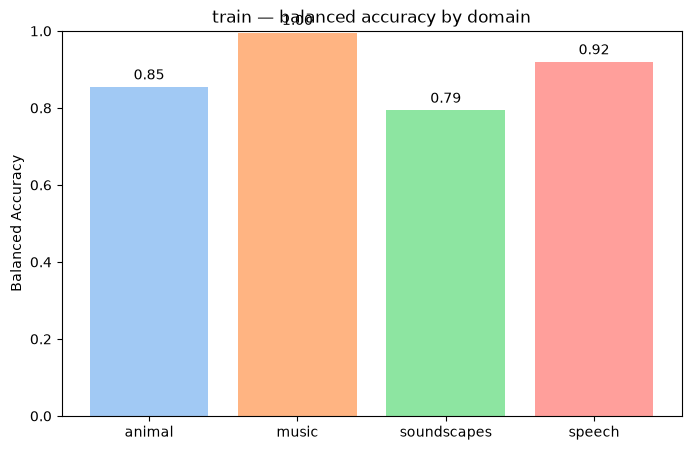

FRAME_DANN_BILSTM_SAMPLER


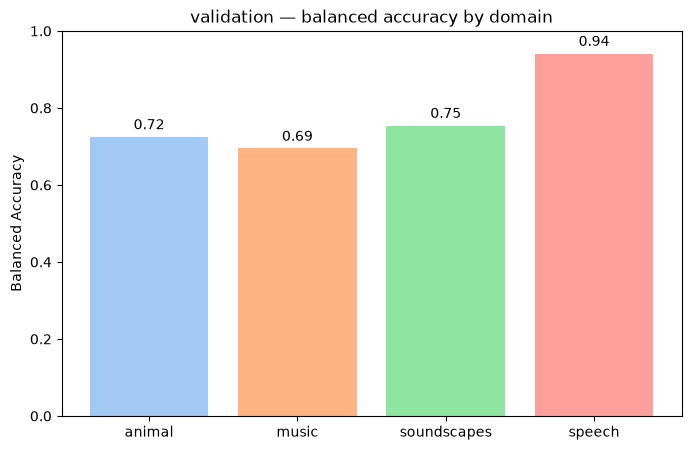

In [6]:
for run in ("frame_bilstm_sampler", "frame_dann_bilstm_sampler"):
    for split_name in ("train", "validation"):
        print(f"{run.upper()}")
        evaluation.plot_domain_metric_bar(all_reports[run], split_name=split_name, metric="balanced_accuracy", filename=f"plots/{run}/{split_name}_domain_summary.png")

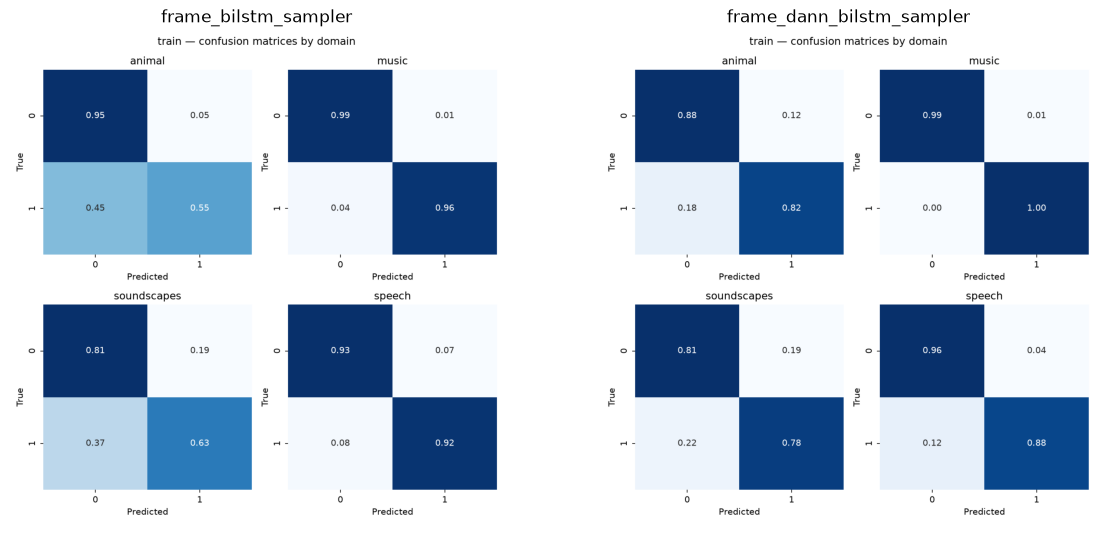

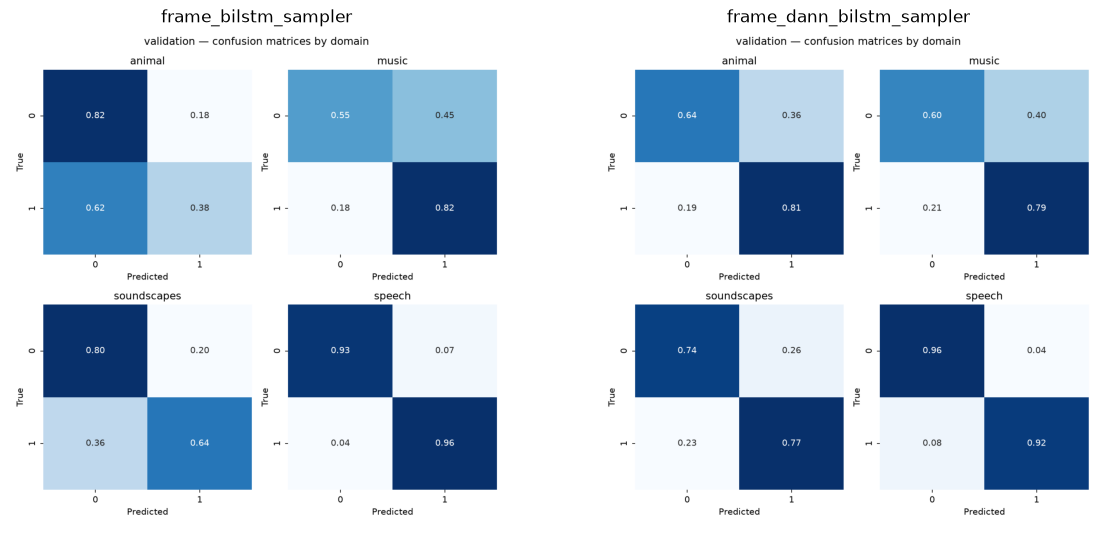

In [7]:
for split_name in ("train", "validation"):
    fig, axes = plt.subplots(1, 2, figsize=(14, 7))
    for ax, run in zip(axes, ("frame_bilstm_sampler", "frame_dann_bilstm_sampler")):
        img = mpimg.imread(f"outputs/plots/confusion_matrices/{run}/{split_name}_combined_cf_matrix.png")
        ax.imshow(img)
        ax.set_title(run)
        ax.axis("off")
    plt.show()